# Missing-data patterns

The missing-data pattern of simulated data under the three mechanisms (MCAR, MAR, MNAR), and of
`nhanes`. The pattern shows which variables are missing together; it cannot tell the mechanisms
apart.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plotting import md_pattern_like, plot_missing_data_pattern

plt.rcParams["figure.dpi"] = 72  # keeps the stored images small

## 1. Simulated data

Four standard normal variables, 300 rows. About 15% of the cells are deleted:

- **MCAR**: each cell independently;
- **MAR**: the probability that a value is missing grows with the value of the next variable;
- **MNAR**: the probability grows with the value itself.

In [2]:
def simulate_missingness(n=300, p=4, seed=42):
    rng = np.random.default_rng(seed)
    full = pd.DataFrame(rng.normal(size=(n, p)), columns=[f"var{i + 1}" for i in range(p)])

    def scaled(column):  # 0 for the smallest value, 1 for the largest
        return (column - column.min()) / (column.max() - column.min())

    mcar = full.mask(rng.random((n, p)) < 0.15)

    mar = full.copy()
    for i, col in enumerate(full.columns):
        driver = full.iloc[:, (i + 1) % p]  # the next variable, which stays observed here
        mar.loc[rng.random(n) < 0.3 * scaled(driver), col] = np.nan

    mnar = full.copy()
    for col in full.columns:
        mnar.loc[rng.random(n) < 0.3 * scaled(full[col]), col] = np.nan

    return {"MCAR": mcar, "MAR": mar, "MNAR": mnar}


data = simulate_missingness()
for name, frame in data.items():
    print(f"{name}: {frame.isna().mean().mean():.1%} of the cells missing")

MCAR: 14.5% of the cells missing
MAR: 14.2% of the cells missing
MNAR: 15.0% of the cells missing


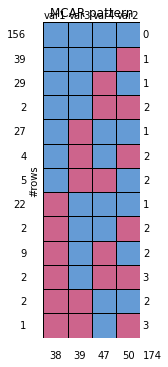

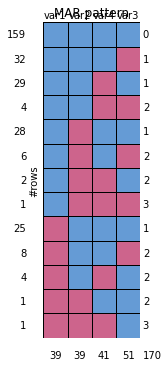

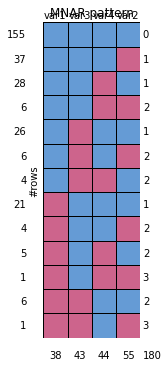

In [3]:
for name, frame in data.items():
    plot_missing_data_pattern(md_pattern_like(frame), title=f"{name} pattern")

The three patterns look alike: whether missingness depends on observed or on unobserved values
cannot be read from the pattern. It has to come from knowledge of how the data were collected,
and the imputation model should include the variables that may explain the missingness.

## 2. nhanes

In [4]:
nhanes = pd.read_csv("data/nhanes.csv")
pattern_nhanes = md_pattern_like(nhanes)
pattern_nhanes

,age,hyp,bmi,chl,#miss_row
#rows,,,,,
13,1,1,1,1,0
3,1,1,1,0,1
1,1,1,0,1,1
1,1,0,0,1,2
7,1,0,0,0,3
#miss_col,0,8,9,10,27


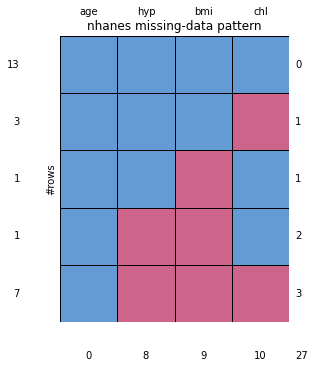

In [5]:
plot_missing_data_pattern(pattern_nhanes, title="nhanes missing-data pattern");

R's `nhanes2` is the same data with `age` and `hyp` as factors. The pattern depends only on which
cells are missing, so it is the same:

In [6]:
nhanes2 = nhanes.astype({"age": "category", "hyp": "category"})
md_pattern_like(nhanes2).equals(pattern_nhanes)

True